# 対数アンプと逆対数アンプ

**対数アンプ**(LOG)は、入力の**対数**に比例した電圧を出す回路です。入力が 10 倍になるたびに、出力が同じだけ(たとえば 1 V)上がります。光の強さや音の大きさのように、何桁にもわたって変わる信号を、1 つの目盛りに収めるのに使います(dB の表示、光センサー)。

**逆対数アンプ**(ANTILOG、指数アンプ)はその逆で、入力が 1 V 上がるたびに、出力が決まった倍率(たとえば 10 倍、2 倍)で大きくなります。シンセサイザーで 1 V ごとに音の高さを 1 オクターブ(周波数 2 倍)上げる「1 V/oct」や、dB で決めたゲインを倍率に戻すところで使います。

この回では、対数アンプの入出力の関係、三角波を入れて「圧縮」された形を見ること、逆対数アンプの入出力の関係、の 3 つを見ます。

## 回路

![対数アンプ](01_log/circuit_log.svg) ![逆対数アンプ](01_log/circuit_antilog.svg)

左が対数アンプ、右が逆対数アンプです。どちらも反転増幅(1-1)の抵抗の 1 つを**ダイオード**に置きかえたものです。

ダイオードの電流は、電圧に対して指数関数的に増えます($I = I_S\,e^{V/V_T}$、$V_T$ は約 26 mV)。逆に見ると、ダイオードの電圧は電流の対数です。

- **対数アンプ**:入力の電流 $V_\mathrm{in}/R$ が帰還のダイオードを流れるので、出力はダイオードの電圧、つまり $-V_T \ln(V_\mathrm{in}/(R I_S))$ になります。入力が 10 倍になるごとに、出力は約 60 mV ずつ変わります。
- **逆対数アンプ**:入力にかかったダイオードの電圧に応じた指数関数の電流が $R_f$ を流れるので、出力は $-R_f I_S\,e^{V_\mathrm{in}/V_T}$ です。

実際の回路では、ダイオードの代わりにトランジスタを使い($I_S$ がそろいやすい)、温度の補償と、60 mV/decade を 1 V/decade などに広げる増幅をつけます。

## 原理

Mimic の対数アンプと逆対数アンプは、次の式で計算します(反転させず、目盛りは 10 を底にした対数で決めます)。

$$\text{LOG:}\quad V_\mathrm{out} = V_\mathrm{ref} + \text{slope} \times \log_{10}\frac{V_\mathrm{in} - V_\mathrm{ref}}{\text{unit}}$$

$$\text{ANTILOG:}\quad V_\mathrm{out} = \text{unit} \times 10^{(V_\mathrm{in} - V_\mathrm{ref})/\text{slope}}$$

| | LOG | ANTILOG |
|---|---|---|
| slope | 入力が 10 倍で出力が slope(V)上がる | 入力が slope(V)上がると出力が 10 倍 |
| unit | 入力 − Vref = unit のとき、出力 = Vref | 入力 = Vref のとき、出力 = unit |
| 入力 | Vref より上の大きさ(Vref 以下では出力が下に張りつく) | Vref を中心にした電圧 |
| 出力 | Vref を中心にした電圧 | **0 V から**の大きさ |

slope と unit が同じなら、LOG と ANTILOG はたがいに逆の計算です。

**範囲**:Mimic の出力は 0.1〜4.9 V ほどしか出せないので、0 V からの大きさで表せるのは 0.1〜4.9 V、約 1.7 桁です。LOG の入力も、Vref(2.5 V)から上の 0.01〜2.4 V ほど(2 桁あまり)が使えます。入力が Vref に近いところでは、Vref の数 mV のずれも、対数では大きなずれになります(0.01 V に 5 mV のずれがあると、0.18 桁)。

![対数と逆対数(模式図)](01_log/response.svg)

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.log(slope, unit)` | `mimic.setLog(slope, unit)` | slope(V/decade、負なら入力が大きいほど出力が下がる)、unit(V) |
| `lab.mimic.antilog(slope, unit)` | `mimic.setAntilog(slope, unit)` | slope(V/decade)、unit(V)。1 V で 2 倍(1 V/oct)にするには slope = 1 / log10(2) = 3.32 |

- 既定は slope = 1 V/decade、unit = 0.5 V です。
- 下の準備のセルの `dc_sweep` は、入力の直流をいくつか変えながら、入力と出力の平均を測ります。測っているあいだは、それぞれの入力での波形を 1 枚の図に描きかえ、最後の 1 枚が残ります。`scope_xy` は、波形と、入力を横軸・出力を縦軸にした入出力特性を並べて描きます。

## 準備:測定器につなぐ

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from mimiclab import MimicLab

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.5, mimic=20261125)

In [2]:
def dc_sweep(inputs, label="output"):
    # Puts each DC voltage on the input and returns the measured (input, output) in V.
    # The plot shows the waveforms at each input while measuring (the last one stays).
    fig, ax = plt.subplots(figsize=(8, 3))
    handle = display(fig, display_id=True)
    vin, vout = [], []
    for v in inputs:
        lab.fg.dc(v)
        time.sleep(0.05)
        t, ch1, ch2 = lab.scope.capture(400)   # 20 ms
        vin.append(ch1.mean())
        vout.append(ch2.mean())
        ax.clear()
        ax.plot(t * 1e3, ch1, label="CH1: input")
        ax.plot(t * 1e3, ch2, label=f"CH2: {label}")
        ax.set_ylim(-0.2, 5.2)
        ax.set_title(f"input {vin[-1]:.3f} V: output {vout[-1]:.3f} V")
        ax.set_xlabel("Time [ms]")
        ax.set_ylabel("Voltage [V]")
        ax.grid(True)
        ax.legend(loc="upper right")
        fig.tight_layout()
        if handle is not None:   # None outside a notebook
            handle.update(fig)
    plt.close(fig)   # the display keeps the last picture
    return np.array(vin), np.array(vout)


def scope_xy(t, ch1, ch2, label, theory=None):
    # Left: the waveforms; right: the output against the input (with the theory curve)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
    ax1.plot(t * 1e3, ch1, label="CH1: input")
    ax1.plot(t * 1e3, ch2, label=f"CH2: {label}")
    ax1.set_ylim(-0.2, 5.2)
    ax1.set_xlabel("Time [ms]")
    ax1.set_ylabel("Voltage [V]")
    ax1.grid(True)
    ax1.legend(loc="lower left", bbox_to_anchor=(0, 1), ncol=2, frameon=False)
    ax2.plot(ch1, ch2, ".", ms=2, color="C2", label="measured")
    if theory is not None:
        x = np.linspace(ch1.min(), ch1.max(), 200)
        ax2.plot(x, theory(x), "k--", lw=1, label="theory")
        ax2.legend(loc="upper left", fontsize=8)
    ax2.set_xlim(0, 5)
    ax2.set_ylim(-0.2, 5.2)
    ax2.set_aspect("equal")
    ax2.set_xlabel("CH1: input [V]")
    ax2.set_ylabel("CH2: output [V]")
    ax2.grid(True)
    fig.tight_layout()
    plt.show()

## 実験 1:対数アンプの入出力

slope = 1 V/decade、unit = 0.5 V にして、入力を Vref から 0.03〜2 V 上の直流にしながら、出力を測ります。横軸を対数の目盛り(入力 − Vref)にすると、出力は傾き 1 V/decade の直線になり、0.5 V のところで 2.5 V(Vref)を通るはずです。

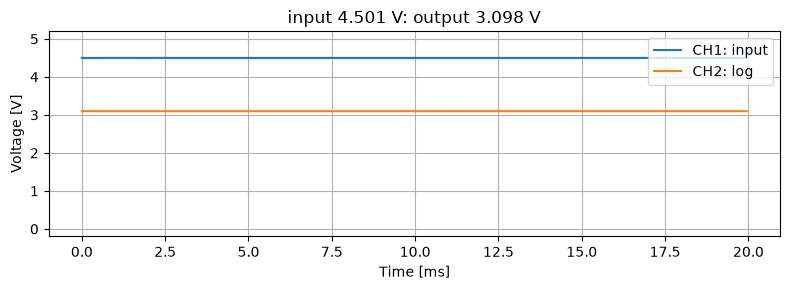

input - Vref  0.031 V: output 1.321 V (theory 1.299 V)
input - Vref  0.051 V: output 1.525 V (theory 1.508 V)
input - Vref  0.101 V: output 1.812 V (theory 1.805 V)
input - Vref  0.201 V: output 2.107 V (theory 2.104 V)
input - Vref  0.501 V: output 2.500 V (theory 2.501 V)
input - Vref  1.000 V: output 2.798 V (theory 2.801 V)
input - Vref  2.001 V: output 3.098 V (theory 3.102 V)
slope from the measurement: 0.985 V / decade (setting 1.0)


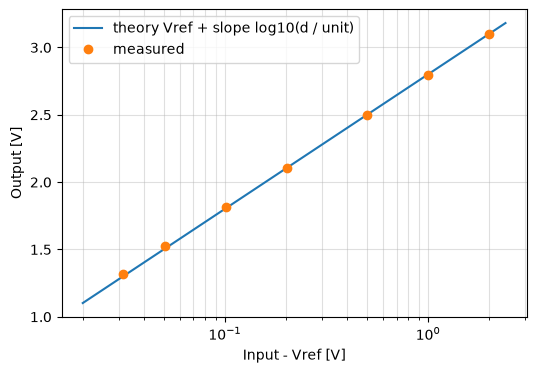

In [3]:
SLOPE, UNIT = 1.0, 0.5
lab.mimic.log(SLOPE, UNIT)
d = np.array([0.03, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0])   # input - Vref [V]
vin, vout = dc_sweep(2.5 + d, "log")
for a, b in zip(vin, vout):
    print(f"input - Vref {a - 2.5:6.3f} V: output {b:.3f} V (theory {2.5 + SLOPE * np.log10((a - 2.5) / UNIT):.3f} V)")
fit = np.polyfit(np.log10(vin - 2.5), vout, 1)[0]
print(f"slope from the measurement: {fit:.3f} V / decade (setting {SLOPE})")

fig, ax = plt.subplots(figsize=(6, 4))
x = np.logspace(np.log10(0.02), np.log10(2.4), 100)
ax.semilogx(x, 2.5 + SLOPE * np.log10(x / UNIT), "-", label="theory Vref + slope log10(d / unit)")
ax.semilogx(vin - 2.5, vout, "o", label="measured")
ax.set_xlabel("Input - Vref [V]")
ax.set_ylabel("Output [V]")
ax.grid(True, which="both", alpha=0.4)
ax.legend()
plt.show()

入力が 10 倍になるごとに、出力が 1 V ずつ上がっています。0.03 V と 2 V では入力が 70 倍ちがいますが、出力は 1.8 V の幅に収まります。入力のいちばん小さい点は、Vref や測定器のわずかなずれのため、理論から少し離れることがあります。

## 実験 2:三角波を対数アンプに入れる

2.55〜4.45 V の三角波(20 Hz)を入れます。入力は時間に比例して上下しますが、出力は、入力が小さいところで速く、大きいところでゆっくり変わる形になるはずです。

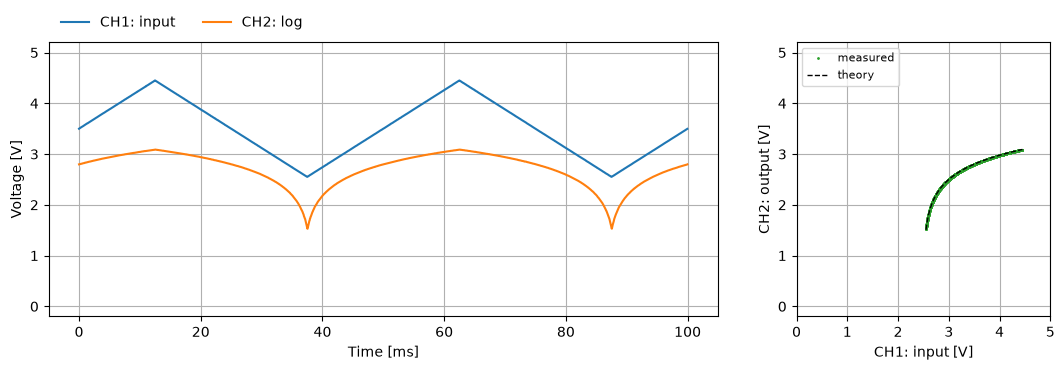

In [4]:
lab.fg.triangle(20, 0.95, 3.5)
lab.mimic.log(1.0, 0.5)
t, ch1, ch2 = lab.scope.capture(2000)   # 0.1 s
scope_xy(t, ch1, ch2, "log", theory=lambda x: 2.5 + np.log10(np.maximum(x - 2.5, 1e-3) / 0.5))

出力は、三角波の谷(入力が Vref に近い)のところで鋭くとがり、山のところで丸くなっています。小さい入力の変化は大きく、大きい入力の変化は小さく表す、という対数の性質で、これが「圧縮」です。人の耳や目も、強さの比(何倍か)を感じるので、音や光の強さは対数(dB)で表します。

## 実験 3:逆対数アンプの入出力

slope = 1 V/decade、unit = 0.5 V の逆対数アンプに、Vref − 0.5 V〜Vref + 0.9 V の直流を入れます。縦軸を対数の目盛りにすると、出力は直線になり、入力が 1 V 上がるごとに 10 倍になるはずです。

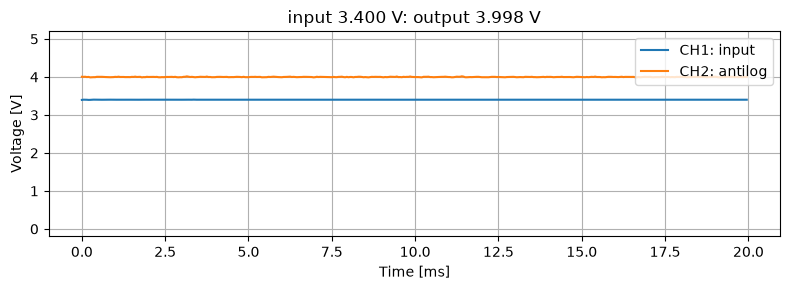

input - Vref -0.500 V: output 0.162 V (theory 0.158 V)
input - Vref -0.300 V: output 0.255 V (theory 0.251 V)
input - Vref -0.099 V: output 0.402 V (theory 0.398 V)
input - Vref +0.001 V: output 0.506 V (theory 0.501 V)
input - Vref +0.101 V: output 0.636 V (theory 0.631 V)
input - Vref +0.301 V: output 1.006 V (theory 1.000 V)
input - Vref +0.501 V: output 1.593 V (theory 1.586 V)
input - Vref +0.700 V: output 2.528 V (theory 2.507 V)
input - Vref +0.900 V: output 3.998 V (theory 3.974 V)
slope from the measurement: 1.004 V / decade (setting 1.0)


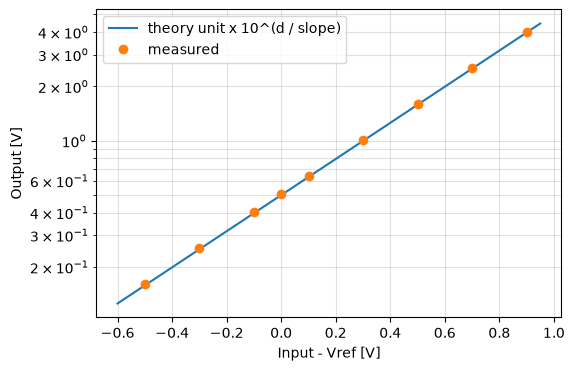

In [5]:
SLOPE, UNIT = 1.0, 0.5
lab.mimic.antilog(SLOPE, UNIT)
x = np.array([-0.5, -0.3, -0.1, 0.0, 0.1, 0.3, 0.5, 0.7, 0.9])   # input - Vref [V]
vin, vout = dc_sweep(2.5 + x, "antilog")
for a, b in zip(vin, vout):
    print(f"input - Vref {a - 2.5:+.3f} V: output {b:.3f} V (theory {UNIT * 10 ** ((a - 2.5) / SLOPE):.3f} V)")
fit = 1 / np.polyfit(vin - 2.5, np.log10(vout), 1)[0]
print(f"slope from the measurement: {fit:.3f} V / decade (setting {SLOPE})")

fig, ax = plt.subplots(figsize=(6, 4))
xx = np.linspace(-0.6, 0.95, 100)
ax.semilogy(xx, UNIT * 10 ** (xx / SLOPE), "-", label="theory unit x 10^(d / slope)")
ax.semilogy(vin - 2.5, vout, "o", label="measured")
ax.set_xlabel("Input - Vref [V]")
ax.set_ylabel("Output [V]")
ax.grid(True, which="both", alpha=0.4)
ax.legend()
plt.show()

出力は 0.16 V から 4 V まで、入力 1.4 V の幅で 25 倍に変わります。出力が 0.1 V に近い下の端では、出力の余裕(0.1 V)と測定器の雑音のため、点が理論から離れやすくなります。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 対数アンプの slope と unit
<details><summary>ヒント</summary>

はじめは `SLOPE = 1.0`、`UNIT = 0.5` です。`SLOPE` を 0.5 → −1.0 と変えてみましょう。0.5 では入出力特性の傾きが半分になり、−1.0 では向きが逆になります(入力が大きいほど出力が下がる。ダイオードで作った回路と同じ向き)。次に `SLOPE = 1.0` に戻して、`UNIT` を 0.1 → 2.0 と変えてみましょう。曲線の形はそのままで、出力が上下にずれます(0.1 では 0.7 V 上、2.0 では 0.6 V 下)。unit は「どの入力を Vref に合わせるか」を決めます。

</details>

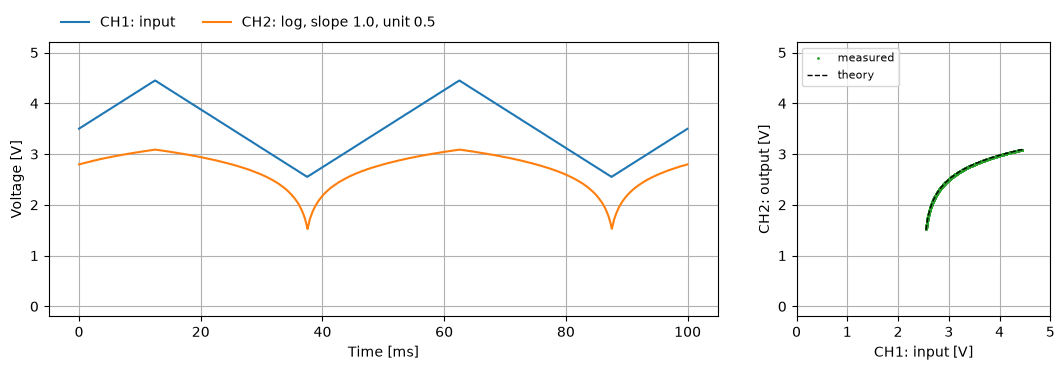

In [6]:
SLOPE = 1.0   # [V / decade]
UNIT = 0.5    # [V]

lab.fg.triangle(20, 0.95, 3.5)
lab.mimic.log(SLOPE, UNIT)
t, ch1, ch2 = lab.scope.capture(2000)
scope_xy(t, ch1, ch2, f"log, slope {SLOPE}, unit {UNIT}",
         theory=lambda x: 2.5 + SLOPE * np.log10(np.maximum(x - 2.5, 1e-3) / UNIT))

### 2. 1 V で 2 倍(1 V/oct)

シンセサイザーの VCO(6-2)は、1 V で 1 オクターブ(周波数 2 倍)上がる指数の特性を使います。逆対数アンプの slope を 1 / log10(2) = 3.32 V/decade にすると、1 V で出力が 2 倍になります。これを直線の VCO の前につなぐと、1 V/oct の VCO になります(2 台を使う講義で)。
<details><summary>ヒント</summary>

はじめは `SLOPE = 3.32` です。入力 1.5、2.5、3.5、4.5 V で、出力は 0.25、0.5、1.0、2.0 V と、1 V ごとに 2 倍になります(表の「ratio」が 2)。`SLOPE` を 1.0 にすると 1 V で 10 倍、`1 / np.log10(1.5)`(5.68)にすると 1 V で 1.5 倍です。10 倍では 1.5 V の入力(0.05 V)が出力の下の余裕より小さく、0.1 V ほどで止まります。

</details>

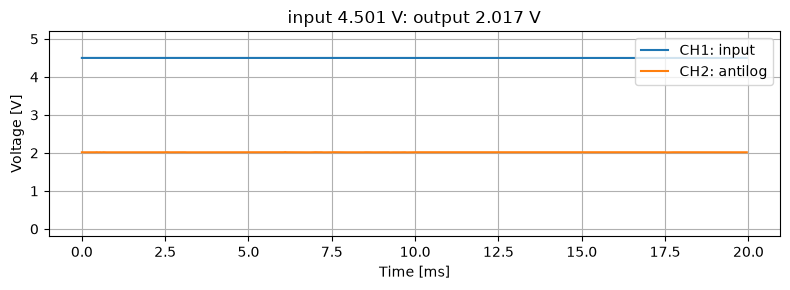

input 1.501 V: output 0.253 V (theory 0.250 V) 
input 2.501 V: output 0.503 V (theory 0.500 V) ratio 1.99
input 3.500 V: output 1.004 V (theory 1.001 V) ratio 1.99
input 4.501 V: output 2.017 V (theory 2.002 V) ratio 2.01


In [7]:
SLOPE = 3.32   # [V / decade]; 1 / log10(2) doubles the output per volt

lab.mimic.antilog(SLOPE, 0.5)
vin, vout = dc_sweep([1.5, 2.5, 3.5, 4.5], "antilog")
for i, (a, b) in enumerate(zip(vin, vout)):
    ratio = f"ratio {b / vout[i - 1]:.2f}" if i else ""
    print(f"input {a:.3f} V: output {b:.3f} V (theory {0.5 * 10 ** ((a - 2.5) / SLOPE):.3f} V) {ratio}")

## まとめ

- 対数アンプは、入力が 10 倍になるたびに出力が同じだけ変わる。何桁にもわたる信号を 1 つの目盛りに収める(圧縮)。
- 逆対数アンプは、入力が一定だけ上がるたびに出力が決まった倍率で大きくなる。1 V/oct など。
- どちらもダイオード(トランジスタ)の、電圧と電流の指数関数の関係を使う。
- Mimic では `log(slope, unit)`、`antilog(slope, unit)`。ANTILOG の出力は 0 V からの大きさ。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [8]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()